<div style="text-align: right"><h4>ФБ-61мп Редько-Шпак Родислав</h4></div>
<h1><center><b>Лабораторна робота №2</b></center></h1>
<h3><center>З предмета "Інтелектуальний аналіз даних"</center></h3>
<h4><center>Тема: "Зниження розмірності, кластеризація та класифікація текстових даних"</center></h4>
<h5><b><center>Хід роботи:</center></b></h5>

<h2>[0] Загальна інформація</h2>

Метою роботи є ознайомлення з базовими методами навчання без учителя та обробки текстів: зниженням розмірності, візуалізацією і кластеризацією даних, а також класифікацією текстів за допомогою Scikit-learn.

У перших двох частинах використовується датасет TUANDROMD з лаби 1. На ньому треба застосувати PCA і t-SNE, порівняти класифікацію до і після PCA, а потім кластеризувати дані K-Means без міток. У третій частині потрібен текстовий датасет з мітками. Тут обрано описи вразливостей CVE за 2024 рік, де класом є тип вразливості (XSS, SQL-ін'єкція, CSRF).

Спочатку було підключено бібліотеки.

In [4]:
import warnings
warnings.filterwarnings('ignore')

import re
import string
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (f1_score, silhouette_score, adjusted_rand_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from wordcloud import WordCloud

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('всьо ок')

всьо ок


<h2>[I] Зниження розмірності та візуалізація даних</h2>

<p align="center"><i><ins>[I.a] Підготовка даних</ins></i></p>


Дані підготовлено так само, як у лабі 1: видалено порожній рядок, виправлено назви колонок, прибрано дублікати і ознаки, які всюди дорівнюють нулю.

In [5]:
df = pd.read_csv('TUANDROMD.csv')
df.columns = (df.columns.str.replace('goodwareTIFICATION', 'NOTIFICATION')
                         .str.replace('DIAGgoodwareSTIC', 'DIAGNOSTIC')
                         .str.replace('Kgoodwarewn', 'Known'))
target = 'Label'

# та сама обробка, що й у Lab 1
df = df.dropna()
df[target] = df[target].map({'goodware': 0, 'malware': 1})
data = df.drop_duplicates().reset_index(drop=True)

features = [c for c in data.columns if c != target and data[c].nunique() > 1]
X = data[features].astype(int)
y = data[target]

print('Розмір даних:', X.shape)
print(y.value_counts().rename({0: 'goodware', 1: 'malware'}))

Розмір даних: (662, 199)
Label
goodware    531
malware     131
Name: count, dtype: int64


Залишилось 662 застосунки і 199 ознак. Поділ на train і test теж такий самий, як у лабі 1, шоб результати можна було порівняти.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (496, 199) | Test: (166, 199)


<p align="center"><i><ins>[I.b] PCA</ins></i></p>


PCA навчено тільки на навчальній вибірці. Спочатку подивимось, скільки компонент потрібно, щоб зберегти різну частку дисперсії.

для 80% дисперсії потрібно компонент: 25
для 90% дисперсії потрібно компонент: 39
для 95% дисперсії потрібно компонент: 54
для 99% дисперсії потрібно компонент: 85

частка дисперсії перших 3 компонент: [0.202 0.128 0.051]


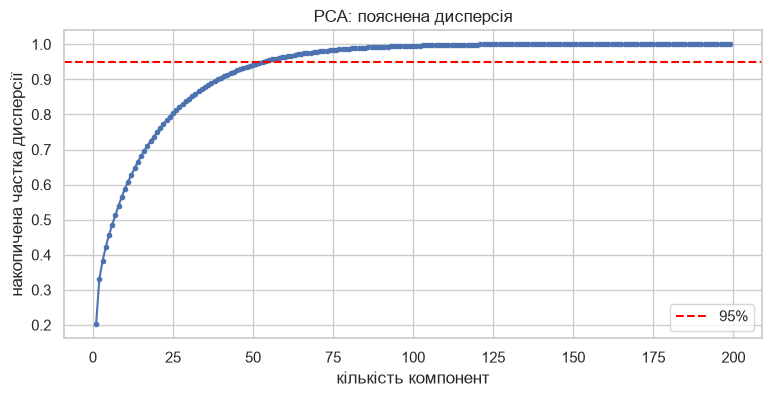

In [7]:
pca_full = PCA().fit(X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)

for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'для {t:.0%} дисперсії потрібно компонент: {np.argmax(cum >= t) + 1}')
print('\nчастка дисперсії перших 3 компонент:', pca_full.explained_variance_ratio_[:3].round(3))

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cum) + 1), cum, marker='.')
plt.axhline(0.95, color='red', ls='--', label='95%')
plt.xlabel('кількість компонент'); plt.ylabel('накопичена частка дисперсії')
plt.title('PCA: пояснена дисперсія')
plt.legend()
plt.show()

Перша компонента пояснює близько 20% дисперсії, перші три разом близько 38%. Щоб зберегти 95% дисперсії, достатньо 54 компонент замість 199, тобто ознак стає майже вчетверо менше. Крива росте досить плавно, тобто інформація розмазана по багатьох напрямках, і однієї-двох головних компонент тут не вистачить.

StandardScaler перед PCA не використовувався, бо всі ознаки і так 0 або 1, а в лабі 1 було видно, що після стандартизації рідкісні дозволи стають дуже великими. Для порівняння:

In [8]:
from sklearn.preprocessing import StandardScaler

cum_sc = np.cumsum(PCA().fit(StandardScaler().fit_transform(X_train)).explained_variance_ratio_)
print('з StandardScaler для 95% дисперсії потрібно компонент:', np.argmax(cum_sc >= 0.95) + 1)

з StandardScaler для 95% дисперсії потрібно компонент: 69


Зі стандартизацією для тих самих 95% потрібно вже 69 компонент, тобто стиснення гірше.

<p align="center"><i><ins>[I.c] Класифікація до і після PCA</ins></i></p>


Для порівняння взято Random Forest з найкращими параметрами з лаби 1 (300 дерев, глибина 20). Його навчено на всіх 199 ознаках і на 54 компонентах PCA. Час навчання рахується як медіана з 5 запусків.

In [9]:
def fit_time(model, X_, y_, repeats=5):
    # медіана часу навчання за кількома запусками, у мілісекундах
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        model.fit(X_, y_)
        times.append(time.perf_counter() - t0)
    return np.median(times) * 1000

rf = RandomForestClassifier(n_estimators=300, max_depth=20, random_state=RANDOM_STATE)  # найкращі параметри з Lab 1

# до PCA
cv_before = cross_val_score(rf, X_train, y_train, cv=cv, scoring='f1').mean()
t_before = fit_time(rf, X_train, y_train)
f1_before = f1_score(y_test, rf.predict(X_test))

# після PCA (95% дисперсії)
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
t0 = time.perf_counter()
X_train_pca = pca.fit_transform(X_train)
t_pca = (time.perf_counter() - t0) * 1000
X_test_pca = pca.transform(X_test)

rf_pca = Pipeline([('pca', PCA(n_components=0.95, random_state=RANDOM_STATE)), ('rf', rf)])
cv_after = cross_val_score(rf_pca, X_train, y_train, cv=cv, scoring='f1').mean()
t_after = fit_time(rf, X_train_pca, y_train)
f1_after = f1_score(y_test, rf.predict(X_test_pca))

pd.DataFrame({
    'кількість ознак': [X_train.shape[1], pca.n_components_],
    'CV F1 (malware)': [cv_before, cv_after],
    'test F1 (malware)': [f1_before, f1_after],
    'навчання RF, мс': [t_before, t_after],
    'навчання PCA, мс': [0, t_pca],
}, index=['до PCA', 'після PCA (95%)']).round(3)

,кількість ознак,CV F1 (malware),test F1 (malware),"навчання RF, мс","навчання PCA, мс"
до PCA,199,0.907,0.875,139.164,0.000
після PCA (95%),54,0.764,0.847,265.852,6.722


Після PCA якість помітно впала, на крос-валідації F1 знизився з 0.907 до 0.764, на тесті з 0.875 до 0.847. Причина в тому, як працює ліс. Дерево ставить питання до окремих ознак, наприклад "чи є дозвіл RECEIVE_SMS". А кожна компонента PCA є сумішшю всіх дозволів одразу, тому такі прості правила вже не побудуєш. До того ж PCA зберігає напрямки з найбільшою дисперсією, а рідкісні, але важливі дозволи мають маленьку дисперсію і частково губляться.

Час навчання навіть зріс приблизно вдвічі, хоча ознак стало менше. Бінарна ознака має лише один поріг для розбиття, а компонента PCA є дробовим числом з сотнями різних значень, тому дерево перебирає набагато більше варіантів.

Також перевірено, як якість залежить від кількості компонент:

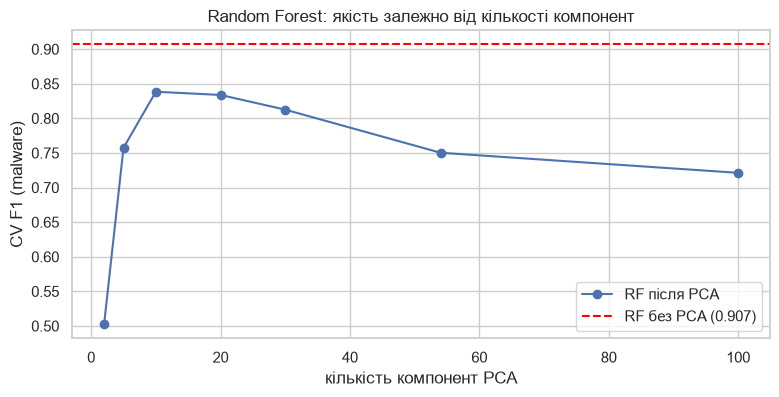

{2: np.float64(0.502), 5: np.float64(0.757), 10: np.float64(0.838), 20: np.float64(0.834), 30: np.float64(0.813), 54: np.float64(0.75), 100: np.float64(0.721)}


In [10]:
n_list = [2, 5, 10, 20, 30, 54, 100]
rows = []
for n in n_list:
    pipe = Pipeline([('pca', PCA(n_components=n, random_state=RANDOM_STATE)), ('rf', rf)])
    rows.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1').mean())

plt.figure(figsize=(9, 4))
plt.plot(n_list, rows, marker='o', label='RF після PCA')
plt.axhline(cv_before, color='red', ls='--', label=f'RF без PCA ({cv_before:.3f})')
plt.xlabel('кількість компонент PCA'); plt.ylabel('CV F1 (malware)')
plt.title('Random Forest: якість залежно від кількості компонент')
plt.legend()
plt.show()

print(dict(zip(n_list, np.round(rows, 3))))

Найкращий результат вийшов при 10-20 компонентах (F1 близько 0.84), але він все одно гірший, ніж без PCA. З двома компонентами інформації вже явно замало, а при 50-100 компонентах якість знову падає, бо серед багатьох дрібних компонент ліс частіше обирає малоінформативні.

Отже, PCA добре стискає ці дані, але для Random Forest користі від нього немає. Тут він корисніший для візуалізації.

<p align="center"><i><ins>[I.d] t-SNE</ins></i></p>


t-SNE застосовано до всіх 662 застосунків, щоб отримати 2D-картинку. Для порівняння поруч показано перші дві компоненти PCA. Кольори відповідають справжнім класам, але самі методи мітки не використовують.

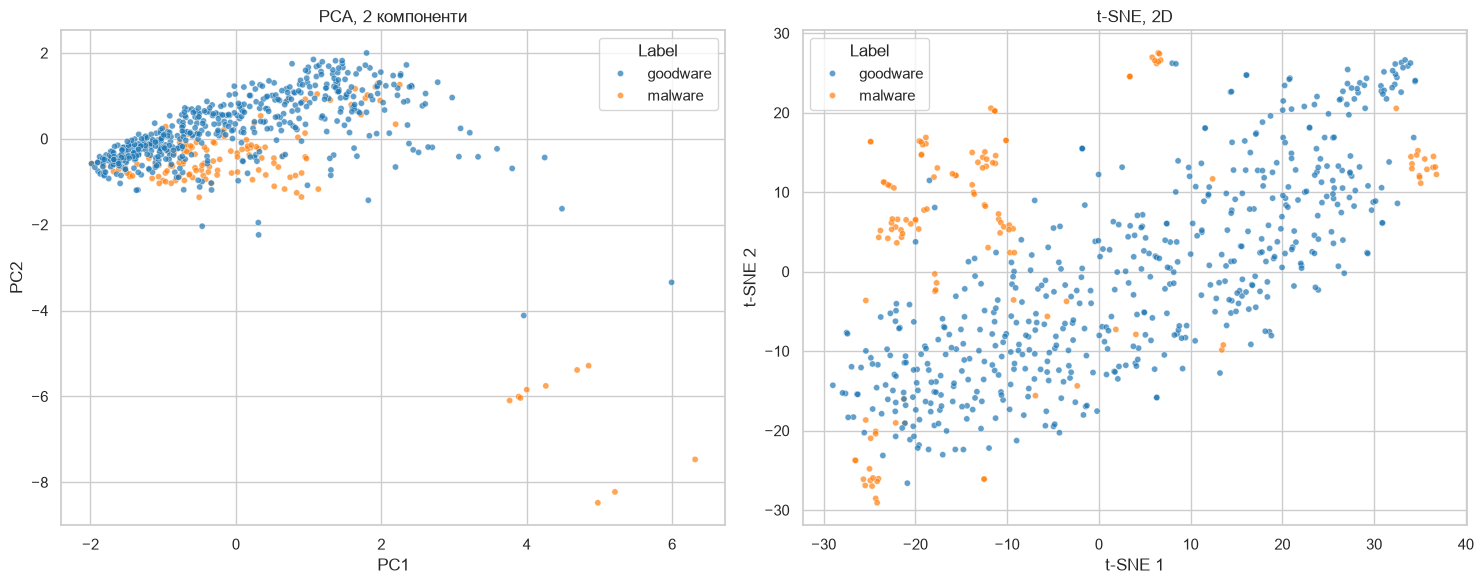

In [11]:
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X)
X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

names = y.map({0: 'goodware', 1: 'malware'})
order = ['goodware', 'malware']
pal = {'goodware': 'tab:blue', 'malware': 'tab:orange'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=names, hue_order=order, palette=pal, s=20, alpha=0.7, ax=axes[0])
axes[0].set_title('PCA, 2 компоненти'); axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=names, hue_order=order, palette=pal, s=20, alpha=0.7, ax=axes[1])
axes[1].set_title('t-SNE, 2D'); axes[1].set_xlabel('t-SNE 1'); axes[1].set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

На PCA класи майже повністю накладаються. Окремо стоїть тільки невелика група шкідливих застосунків внизу справа, це програми, які запитують десятки дозволів одразу (вони ще з'являться в кластеризації).

На t-SNE картинка набагато цікавіша. Шкідливі застосунки утворюють кілька маленьких щільних "островів", переважно зверху. Скоріш за все, кожен такий острів відповідає одному сімейству шкідливого ПЗ з майже однаковим набором дозволів. Звичайні застосунки розкидані однією великою хмарою, бо вони всі різні. Кілька шкідливих точок потрапили всередину цієї хмари. Саме такі застосунки моделі з лаби 1 і пропускали.

t-SNE розділяє класи краще, бо зберігає не загальну дисперсію, а локальне сусідство, тобто хто кому найближчий. Але відстані між островами і їхні розміри на такому графіку нічого не означають, тому для навчання моделей t-SNE не використовують, тільки для візуалізації.

<h2>[II] Кластерний аналіз</h2>

<p align="center"><i><ins>[II.a] Вибір кількості кластерів</ins></i></p>


Кластеризація виконується на тих самих даних, мітки не використовуються. Для K від 2 до 10 пораховано інерцію і середній силует.

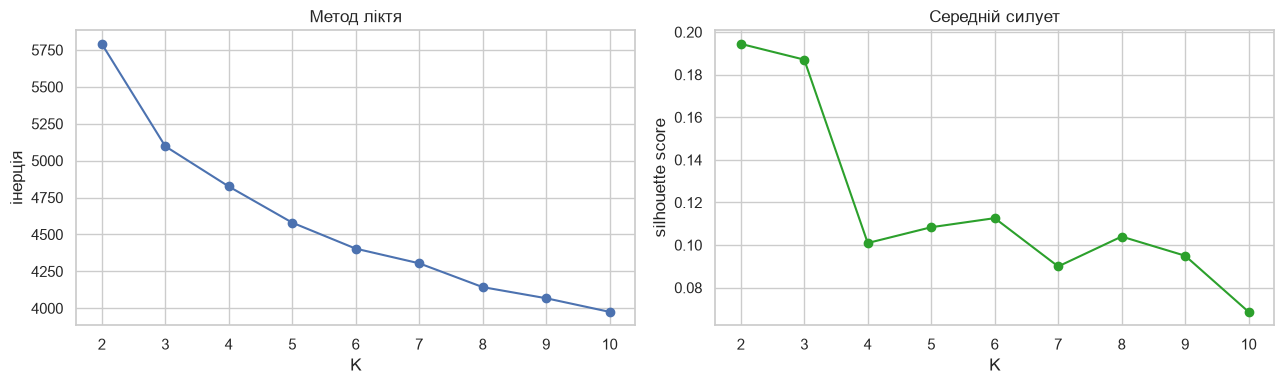

,2,3,4,5,6,7,8,9,10
інерція,5791.331,5097.650,4825.121,4580.009,4403.977,4304.501,4143.279,4067.849,3975.470
silhouette,0.194,0.187,0.101,0.108,0.113,0.090,0.104,0.095,0.069


In [12]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)   # мітки y тут не використовуються
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), inertia, marker='o')
axes[0].set_xlabel('K'); axes[0].set_ylabel('інерція'); axes[0].set_title('Метод ліктя')
axes[1].plot(list(ks), sil, marker='o', color='tab:green')
axes[1].set_xlabel('K'); axes[1].set_ylabel('silhouette score'); axes[1].set_title('Середній силует')
plt.tight_layout()
plt.show()

pd.DataFrame({'інерція': inertia, 'silhouette': sil}, index=list(ks)).round(3).T

Чіткого ліктя немає, інерція спадає досить рівно. Силует найбільший при K = 2 (0.194), при K = 3 майже такий самий (0.187), а далі падає приблизно до 0.1. Самі значення низькі, тобто чітко відокремлених груп у даних немає. Обрано K = 2, а K = 3 перевірено додатково.

<p align="center"><i><ins>[II.b] Кластеризація і візуалізація</ins></i></p>


K-Means з K = 2 навчено на всіх ознаках. Кластери показано на t-SNE з пункту [I.d], а поруч для порівняння справжні класи.

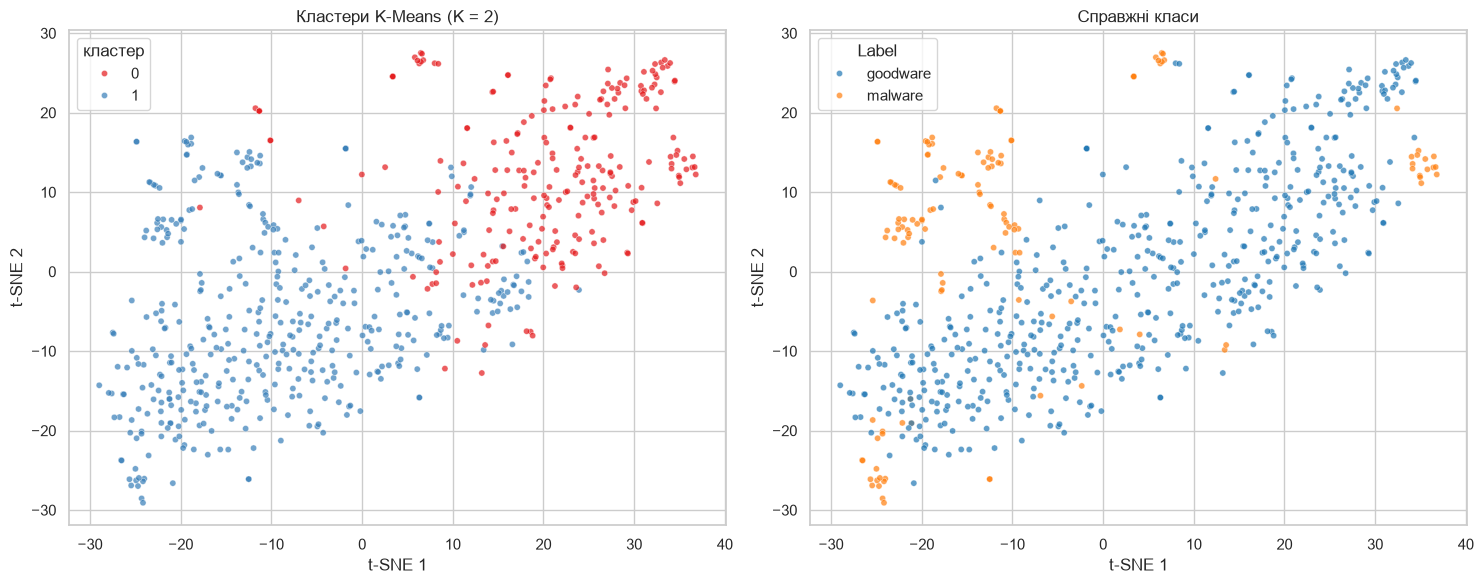

In [13]:
K = 2
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
clusters = km.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=clusters.astype(str), hue_order=sorted(set(clusters.astype(str))), palette='Set1', s=20, alpha=0.7, ax=axes[0])
axes[0].set_title(f'Кластери K-Means (K = {K})'); axes[0].legend(title='кластер')
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=names, hue_order=order, palette=pal, s=20, alpha=0.7, ax=axes[1])
axes[1].set_title('Справжні класи')
for ax in axes:
    ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

K-Means розділив карту приблизно на ліву і праву частину, і це ніяк не схоже на поділ на malware і goodware. Острови шкідливих застосунків потрапили в обидва кластери.

<p align="center"><i><ins>[II.c] Порівняння кластерів зі справжніми класами</ins></i></p>


Порівняння зроблено через таблицю спряженості і скоригований індекс Ренда (ARI), де 1 означає повний збіг, а 0 випадковий поділ.

In [14]:
print(pd.crosstab(clusters, names, rownames=['кластер'], colnames=['клас']))
print('\nARI =', round(adjusted_rand_score(y, clusters), 3))

клас     goodware  malware
кластер                   
0             199       33
1             332       98

ARI = -0.024


В обох кластерах переважають звичайні застосунки, а частка шкідливих там 14% і 23%, тобто майже як у всьому датасеті. ARI близький до нуля, отже знайдені кластери з класами не збігаються. Щоб зрозуміти, як саме K-Means поділив дані, переглянуто профіль кластерів:

In [15]:
perm_cols = [c for c in features if '->' not in c]
api_cols = [c for c in features if '->' in c]

def short(c):
    return c.split('->')[-1] + '()' if '->' in c else c

def profile(labels):
    prof = pd.DataFrame({
        'об\'єктів': pd.Series(labels).value_counts().sort_index(),
        'частка malware': y.groupby(labels).mean().round(2),
        'медіана дозволів': X[perm_cols].sum(axis=1).groupby(labels).median(),
        'медіана API': X[api_cols].sum(axis=1).groupby(labels).median(),
    })
    prof.index.name = 'кластер'
    return prof

print(profile(clusters), '\n')

# ознаки, частота яких найбільше відрізняється між кластерами
means = X.groupby(clusters).mean()
top_diff = (means.max() - means.min()).sort_values(ascending=False).head(8).index
means[top_diff].rename(columns=short).T.round(2)

         об'єктів  частка malware  медіана дозволів  медіана API
кластер                                                         
0             232            0.14              11.0         12.0
1             430            0.23               4.0          3.0 



,0,1
getNetworkOperatorName(),0.81,0.07
getNetworkOperator(),0.89,0.17
ACCESS_WIFI_STATE,0.74,0.13
getSimOperator(),0.61,0.04
load(),0.72,0.15
getLastKnownLocation(),0.75,0.24
loadLibrary(),0.65,0.14
openConnection(),0.93,0.44


Тепер зрозуміло, що K-Means поділив застосунки за "розміром". У кластері 0 зібрались функціональні застосунки з медіаною 11 дозволів і 12 викликів API. Більшість з них звертається до мережі, Wi-Fi, геолокації, інформації про оператора, завантажує бібліотеки. У кластері 1 прості застосунки з 4 дозволами і 3 викликами API. Це логічно, бо K-Means просто групує точки, які близькі за відстанню, а найбільша різниця між застосунками саме в тому, скільки функцій вони використовують. Дозволи, які відрізняють шкідливі програми (SMS, автозапуск), є лише кількома ознаками зі 199 і на відстань впливають мало.

Для K = 3:

In [16]:
clusters3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
print(pd.crosstab(clusters3, names, rownames=['кластер'], colnames=['клас']), '\n')
print('ARI =', round(adjusted_rand_score(y, clusters3), 3), '\n')
profile(clusters3)

клас     goodware  malware
кластер                   
0               2       10
1             209       21
2             320      100 

ARI = -0.001 



,об'єктів,частка malware,медіана дозволів,медіана API
кластер,,,,
0,12,0.83,73.0,5.0
1,230,0.09,10.0,12.0
2,420,0.24,4.0,3.0


При K = 3 з'явився окремий кластер з 12 застосунків, 10 з яких шкідливі, з медіаною 73 дозволи. Це ті самі програми, які запитують майже все, їх було видно ще в лабі 1 і на PCA вище. Два інші кластери майже повторюють поділ з K = 2, тому ARI все одно близький до нуля.

Отже, кластерна структура не відповідає реальним класам. K-Means знайшов іншу структуру даних (великі і прості застосунки), а шкідливість визначається конкретними комбінаціями дозволів, і для неї потрібна саме класифікація.

<h2>[III] Обробка та класифікація текстових даних</h2>

<p align="center"><i><ins>[III.a] Датасет</ins></i></p>


Для текстової частини зібрано власний датасет з офіційного списку вразливостей CVE (https://github.com/CVEProject/cvelistV5). Кожна CVE має короткий текстовий опис і тип вразливості за класифікацією CWE. Взято три найпоширеніші веб-вразливості:

- CWE-79, міжсайтовий скриптинг (XSS);
- CWE-89, SQL-ін'єкція (SQLi);
- CWE-352, міжсайтова підробка запиту (CSRF).

Зі всіх опублікованих CVE за 2024 рік залишено ті, що мають рівно один тип CWE, прибрано однакові описи і випадково взято по 1000 описів кожного класу.

In [17]:
texts = pd.read_csv('cve_2024_vuln_types.csv')
print('Розмір:', texts.shape)
print(texts['label'].value_counts(), '\n')
print('Довжина опису (символів):', texts['description'].str.len().describe()[['mean', '50%', 'min', 'max']].round(0).to_dict())
texts.head()

Розмір: (3000, 4)
label
SQLi    1000
CSRF    1000
XSS     1000
Name: count, dtype: int64 

Довжина опису (символів): {'mean': 342.0, '50%': 338.0, 'min': 48.0, 'max': 3065.0}


,cve_id,cwe,label,description
0,CVE-2024-2330,CWE-89,SQLi,A vulnerability was found in Netentsec NS-ASG ...
1,CVE-2024-6014,CWE-89,SQLi,A vulnerability classified as critical has bee...
2,CVE-2024-7306,CWE-89,SQLi,"A vulnerability, which was classified as criti..."
3,CVE-2024-43316,CWE-352,CSRF,Cross-Site Request Forgery (CSRF) vulnerabilit...
4,CVE-2024-37561,CWE-79,XSS,Improper Neutralization of Input During Web Pa...


Датасет збалансований, 3000 описів по 1000 на клас. Середня довжина опису близько 340 символів (2-4 речення). Приклад з кожного класу:

In [18]:
for lbl in ['XSS', 'SQLi', 'CSRF']:
    print(f'--- {lbl} ---')
    print(texts.loc[texts['label'] == lbl, 'description'].iloc[0], '\n')

--- XSS ---
Improper Neutralization of Input During Web Page Generation (XSS or 'Cross-site Scripting') vulnerability in Jamie Bergen Plugin Notes Plus allows Stored XSS.This issue affects Plugin Notes Plus: from n/a through 1.2.6. 

--- SQLi ---
A vulnerability was found in Netentsec NS-ASG Application Security Gateway 6.3. It has been classified as critical. This affects an unknown part of the file /protocol/index.php. The manipulation of the argument IPAddr leads to sql injection. It is possible to initiate the attack remotely. The exploit has been disclosed to the public and may be used. The identifier VDB-256281 was assigned to this vulnerability. NOTE: The vendor was contacted early about this disclosure but did not respond in any way. 

--- CSRF ---
Cross-Site Request Forgery (CSRF) vulnerability in Checkout Plugins Stripe Payments For WooCommerce by Checkout.This issue affects Stripe Payments For WooCommerce by Checkout: from n/a through 1.9.1. 



Описи пишуть різні організації, і в кожної свій шаблон. Наприклад, багато SQLi-описів мають шаблон VulDB ("The manipulation of the argument ... leads to sql injection"), а XSS і CSRF часто стосуються плагінів WordPress. Також видно, що назва класу майже завжди прямо є в тексті. Це важливо для оцінки результатів, тому окремо перевірено в пункті [III.f].

<p align="center"><i><ins>[III.b] Передобробка тексту</ins></i></p>


Тексти переведено в нижній регістр, прибрано посилання, шляхи до файлів, числа і версії, пунктуацію, стоп-слова і окремі літери.

In [19]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'https?://\S+', ' ', text)     # посилання
    text = re.sub(r'\S*/\S*', ' ', text)          # шляхи до файлів (/admin/index.php)
    text = re.sub(r'\d+', ' ', text)              # числа і версії
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    return ' '.join(words)

texts['clean'] = texts['description'].map(clean_text)

print('ДО:   ', texts['description'].iloc[0][:300])
print('\nПІСЛЯ:', texts['clean'].iloc[0][:300])

ДО:    A vulnerability was found in Netentsec NS-ASG Application Security Gateway 6.3. It has been classified as critical. This affects an unknown part of the file /protocol/index.php. The manipulation of the argument IPAddr leads to sql injection. It is possible to initiate the attack remotely. The exploi

ПІСЛЯ: vulnerability netentsec ns asg application security gateway classified critical affects unknown file manipulation argument ipaddr leads sql injection possible initiate attack remotely exploit disclosed public used identifier vdb assigned vulnerability note vendor contacted early disclosure did respo


Після обробки залишились лише змістовні слова. Лематизацію я не робив, бо описи написані формальною мовою за шаблонами, і різних форм одного слова там мало.

<p align="center"><i><ins>[III.c] WordCloud</ins></i></p>


Деякі слова часто трапляються в усіх трьох класах, бо описують CVE загалом, а не тип вразливості. тому для WordCloud їх прибрано.

In [20]:
from collections import Counter

labels = ['XSS', 'SQLi', 'CSRF']
counts = {l: Counter(' '.join(texts.loc[texts['label'] == l, 'clean']).split()) for l in labels}

# слова, які є в топ-40 одразу всіх трьох класів, нічого не кажуть про тип вразливості
common = set.intersection(*[{w for w, _ in counts[l].most_common(40)} for l in labels])
print('Спільні часті слова:', sorted(common))

Спільні часті слова: ['affects', 'allows', 'issue', 'plugin', 'possible', 'user', 'versions', 'vulnerability', 'wordpress']


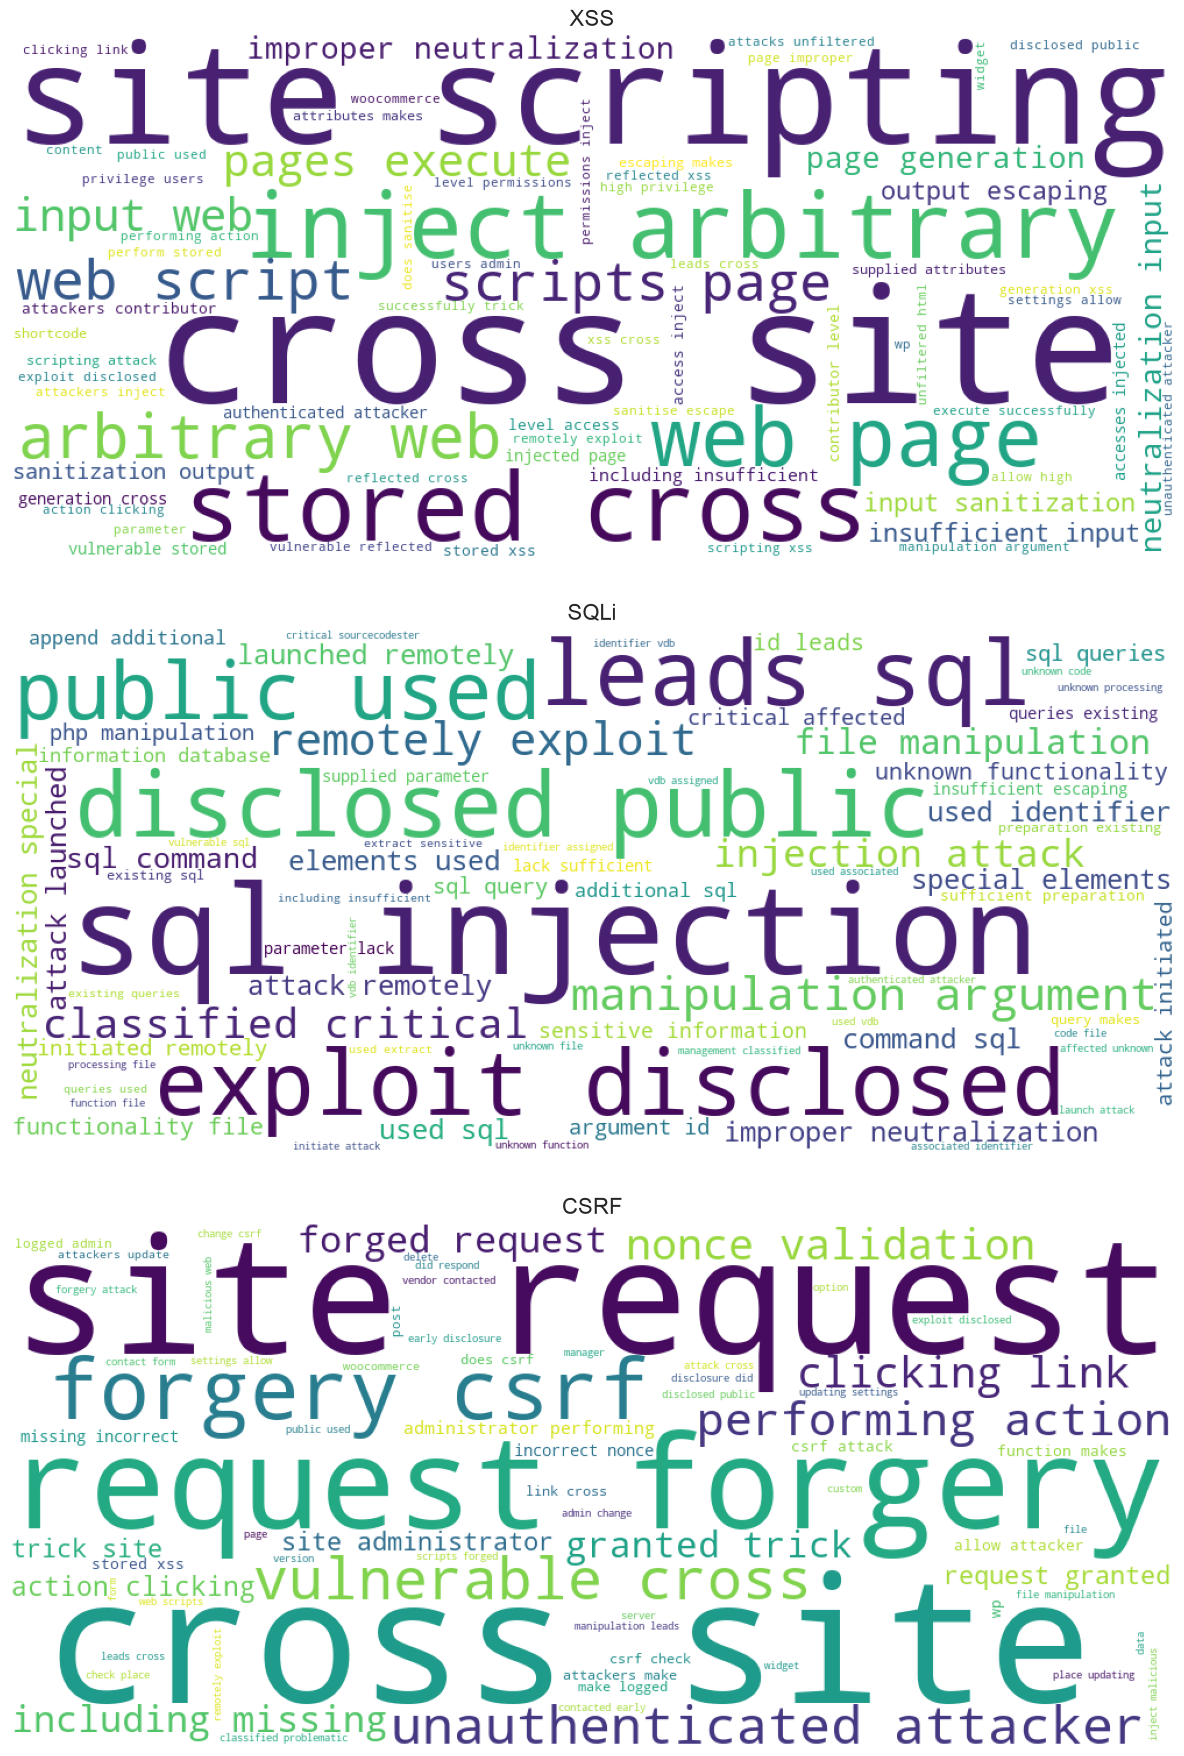

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(12, 18))
for ax, l in zip(axes, labels):
    wc = WordCloud(width=1000, height=450, background_color='white', stopwords=common,
                   collocations=True, max_words=70, random_state=RANDOM_STATE)
    wc.generate(' '.join(texts.loc[texts['label'] == l, 'clean']))
    ax.imshow(wc); ax.axis('off'); ax.set_title(l, fontsize=16)
plt.tight_layout()
plt.show()

Для кожного класу видно свої характерні слова і словосполучення.

У XSS це "cross site scripting", "web page", "inject arbitrary", "stored", "input sanitization", "output escaping". Тобто описується сама причина вразливості, коли введені дані виводяться на сторінку без екранування і зловмисник вставляє туди свій скрипт.

У SQLi найбільші "sql injection", "manipulation argument", "classified critical", "exploit disclosed public". Тут добре видно шаблон VulDB, де майже кожен опис має однакову структуру, і такі вразливості майже завжди позначені як критичні.

У CSRF це "request forgery", "nonce validation", "missing", "clicking link", "site administrator". Описується сценарій, коли адміна змушують перейти за посиланням, а сайт не перевіряє nonce (токен захисту).

Варто звернути увагу, що "cross site" великий і в XSS, і в CSRF, а в CSRF ще трапляється "stored xss". Деякі CSRF-вразливості дозволяють далі провести XSS-атаку, тому ці два класи найлегше сплутати.

<p align="center"><i><ins>[III.d] Векторизація TF-IDF</ins></i></p>


Дані розділено на навчальну і тестову вибірки 75/25 зі стратифікацією і векторизовано через TfidfVectorizer зі словами і парами слів (ngram_range=(1, 2)). Слова, які є лише в одному документі, відкинуто (min_df=2). Векторизатор навчено тільки на навчальній вибірці.

In [22]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    texts['clean'], texts['label'], test_size=0.25, stratify=texts['label'], random_state=RANDOM_STATE)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
T_train = vectorizer.fit_transform(Xt_train)
T_test = vectorizer.transform(Xt_test)

print('Train:', T_train.shape, '| Test:', T_test.shape)
print(f'Ненульових значень у матриці: {T_train.nnz / np.prod(T_train.shape):.2%}')

Train: (2250, 5543) | Test: (750, 5543)
Ненульових значень у матриці: 0.83%


Вийшло 5543 ознаки, а ненульових значень менше 1%, тобто матриця дуже розріджена. Кожен опис містить лише кілька десятків слів з усього словника.

<p align="center"><i><ins>[III.e] Класифікація текстів</ins></i></p>


Порівняно три моделі, які добре підходять для TF-IDF: логістичну регресію, наївний баєсів класифікатор і лінійний SVM. Класи збалансовані, тому основною метрикою взято F1-macro. Для крос-валідації векторизатор теж додано в Pipeline.

In [23]:
text_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Multinomial NB': MultinomialNB(),
    'Linear SVM': LinearSVC(),
}

rows = []
for name, model in text_models.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ('model', model)])
    cv_f1 = cross_val_score(pipe, Xt_train, yt_train, cv=cv, scoring='f1_macro').mean()
    model.fit(T_train, yt_train)
    rows.append({'Модель': name, 'CV F1-macro': cv_f1,
                 'test F1-macro': f1_score(yt_test, model.predict(T_test), average='macro')})

pd.DataFrame(rows).set_index('Модель').round(3)

,CV F1-macro,test F1-macro
Модель,,
Logistic Regression,0.995,0.992
Multinomial NB,0.955,0.950
Linear SVM,0.994,0.992


Логістична регресія і лінійний SVM дали майже однаковий результат (0.992), наївний Баєс слабший (0.95). Він вважає слова незалежними, а тут "cross", "site" і "scripting" майже завжди йдуть разом. Далі розглянуто логістичну регресію.

              precision    recall  f1-score   support

        CSRF      0.988     0.988     0.988       250
        SQLi      1.000     0.992     0.996       250
         XSS      0.988     0.996     0.992       250

    accuracy                          0.992       750
   macro avg      0.992     0.992     0.992       750
weighted avg      0.992     0.992     0.992       750



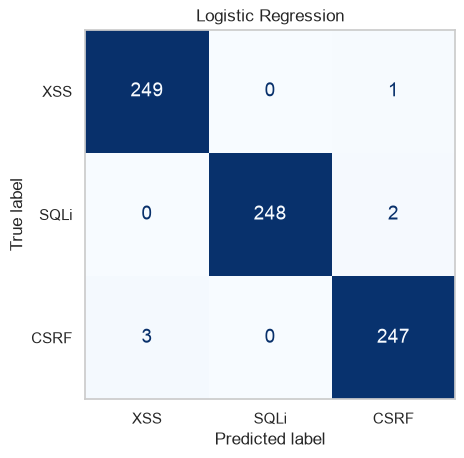

In [24]:
best_txt = text_models['Logistic Regression']
pred = best_txt.predict(T_test)
print(classification_report(yt_test, pred, digits=3))

ConfusionMatrixDisplay(confusion_matrix(yt_test, pred, labels=labels), display_labels=labels).plot(
    cmap='Blues', colorbar=False, text_kw={'fontsize': 14})
plt.grid(False)
plt.title('Logistic Regression')
plt.show()

Модель помилилась лише на 6 описах з 750, найчастіше сплутала CSRF з XSS, як і очікувалось після WordCloud. Але такий результат пояснюється тим, що назва класу зазвичай прямо є в тексті. Це перевірено нижче.

<p align="center"><i><ins>[III.f] Перевірка без ключових слів</ins></i></p>


Щоб перевірити, чи модель розуміє щось, крім назви класу, з описів прибрано всі прямі назви вразливостей ("cross-site scripting", "XSS", "SQL", "injection", "CSRF", "request forgery" тощо), а потім модель навчено заново.

In [25]:
# прибираємо з описів прямі назви класів
KEYWORDS = (r'cross[\s-]*site[\s-]*scripting|cross[\s-]*site[\s-]*request[\s-]*forgery|request[\s-]*forgery'
            r'|\bxss\b|\bcsrf\b|\bxsrf\b|sql[\s-]*injection|\bsqli\b|\bsql\b|\binjection\b'
            r'|cross[\s-]*site|scripting|forgery')
texts['masked'] = texts['description'].str.replace(KEYWORDS, ' ', regex=True, flags=re.I).map(clean_text)
print('Приклад:', texts['masked'].iloc[0][:250], '\n')

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    texts['masked'], texts['label'], test_size=0.25, stratify=texts['label'], random_state=RANDOM_STATE)
vec_m = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
lr_m = LogisticRegression(max_iter=1000).fit(vec_m.fit_transform(Xm_train), ym_train)
pred_m = lr_m.predict(vec_m.transform(Xm_test))

print(classification_report(ym_test, pred_m, digits=3))
print(pd.DataFrame(confusion_matrix(ym_test, pred_m, labels=labels), index=labels, columns=labels))

Приклад: vulnerability netentsec ns asg application security gateway classified critical affects unknown file manipulation argument ipaddr leads possible initiate attack remotely exploit disclosed public used identifier vdb assigned vulnerability note vendor  

              precision    recall  f1-score   support

        CSRF      0.941     0.964     0.953       250
        SQLi      0.931     0.968     0.949       250
         XSS      0.979     0.916     0.946       250

    accuracy                          0.949       750
   macro avg      0.950     0.949     0.949       750
weighted avg      0.950     0.949     0.949       750

      XSS  SQLi  CSRF
XSS   229    13     8
SQLi    1   242     7
CSRF    4     5   241


Навіть без назв класів F1-macro залишився 0.949, тобто впав лише на 4%. Найчастіше модель тепер помиляється на XSS. Щоб зрозуміти, на що вона спирається, виведено слова з найбільшими вагами для кожного класу:

In [ ]:
feat_names = np.array(vec_m.get_feature_names_out())
pd.DataFrame({cls: feat_names[np.argsort(lr_m.coef_[i])[-10:][::-1]]
              for i, cls in enumerate(lr_m.classes_)})

,CSRF,SQLi,XSS
0,issue affects,critical,input
1,affects,classified critical,problematic
2,issue,database,page
3,manipulation leads,command,web
4,actions,special elements,page generation
5,allows issue,neutralization special,neutralization input
6,classified problematic,elements used,input web
7,problematic,special,generation vulnerability
8,logged,used command,generation
9,request,parameter,web page


Частина слів справді описує суть вразливості. Для XSS це "web page generation", "input", а для SQLi "database", "parameter", "special elements used ... command". Але частина з них взята з офіційних назв типів CWE, які автори копіюють в описи. Наприклад, повна назва CWE-89 звучить як "Improper Neutralization of Special Elements used in an SQL Command", і після видалення слова "sql" решта фрази залишилась. Ще модель використовує оцінку критичності з шаблону VulDB, бо SQL-ін'єкції там майже завжди "critical", а XSS і CSRF часто "problematic".

Тобто класифікатор частково вивчив справжні ознаки вразливостей, а частково шаблони конкретних джерел. Для реальних описів, написаних іншим стилем, якість, скоріш за все, буде нижчою.

<h2>[IV] Загальні висновки</h2>

В ході виконання лабораторної роботи було застосовано методи зниження розмірності, кластеризації та класифікації текстів. PCA добре стиснув дані про Android-застосунки, але для Random Forest це погіршило якість і навіть сповільнило навчання, тоді як t-SNE наочно показав окремі групи шкідливих програм. K-Means без міток поділив застосунки за їхньою загальною функціональністю, а не за шкідливістю, тобто кластери і класи не обов'язково збігаються. Класифікатор описів вразливостей показав майже ідеальну якість, але перевірка показала, що частково він спирається на шаблонні фрази в текстах. Отже, високі метрики варто перевіряти і розуміти, що саме вивчила модель.